For the regresstion task I am using a dataset I found on Kaggle that is about crab age prediction.
This dataset was uploaded by Gursewak Singh Sidhu.

# Importing Important Libraries

In [76]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Loading in the Dataset

**This loads in the dataset into the notebook and prints out the rows and columns available in the dataset**

In [77]:
DATA = pd.read_csv("/kaggle/input/datasets/hannahchanjudeh/crab-age-prediction-dataset/CrabAgePrediction.csv")
print("Loaded:", "Crab Age Prediction Dataset")
print("Rows:", len(DATA), "| Columns:", len(DATA.columns))

Loaded: Crab Age Prediction Dataset
Rows: 3893 | Columns: 9


**Here we can view the table**

In [78]:
DATA

,Sex,Length,Diameter,Height,Weight,Shucked Weight,Viscera Weight,Shell Weight,Age
0,F,1.4375,1.1750,0.4125,24.635715,12.332033,5.584852,6.747181,9
1,M,0.8875,0.6500,0.2125,5.400580,2.296310,1.374951,1.559222,6
2,I,1.0375,0.7750,0.2500,7.952035,3.231843,1.601747,2.764076,6
3,F,1.1750,0.8875,0.2500,13.480187,4.748541,2.282135,5.244657,10
4,I,0.8875,0.6625,0.2125,6.903103,3.458639,1.488349,1.700970,6
...,...,...,...,...,...,...,...,...,...
3888,F,1.4625,1.1375,0.3250,24.819987,11.651644,5.854172,6.378637,8
3889,F,1.5500,1.2125,0.4375,34.458817,15.450477,7.172423,9.780577,10
3890,I,0.6250,0.4625,0.1625,2.012815,0.765436,0.524466,0.637864,5
3891,I,1.0625,0.7750,0.2625,10.347568,4.507570,2.338834,2.976698,6


# Exploring the Dataset

**This allows us to check the first five rows**

In [79]:
DATA.head()

,Sex,Length,Diameter,Height,Weight,Shucked Weight,Viscera Weight,Shell Weight,Age
0,F,1.4375,1.1750,0.4125,24.635715,12.332033,5.584852,6.747181,9
1,M,0.8875,0.6500,0.2125,5.400580,2.296310,1.374951,1.559222,6
2,I,1.0375,0.7750,0.2500,7.952035,3.231843,1.601747,2.764076,6
3,F,1.1750,0.8875,0.2500,13.480187,4.748541,2.282135,5.244657,10
4,I,0.8875,0.6625,0.2125,6.903103,3.458639,1.488349,1.700970,6


**And this allows us to check the last five rows**

In [80]:
DATA.tail()

,Sex,Length,Diameter,Height,Weight,Shucked Weight,Viscera Weight,Shell Weight,Age
3888,F,1.4625,1.1375,0.3250,24.819987,11.651644,5.854172,6.378637,8
3889,F,1.5500,1.2125,0.4375,34.458817,15.450477,7.172423,9.780577,10
3890,I,0.6250,0.4625,0.1625,2.012815,0.765436,0.524466,0.637864,5
3891,I,1.0625,0.7750,0.2625,10.347568,4.507570,2.338834,2.976698,6
3892,I,0.7875,0.6125,0.2125,4.068153,1.502523,1.346601,1.417475,8


**This is a shorter way of printing the rows and columns**

In [81]:
DATA.shape

(3893, 9)

**info() shows a summary of the dataset like missing values, row count, data types, and structure** 

In [82]:
DATA.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3893 entries, 0 to 3892
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Sex             3893 non-null   object 
 1   Length          3893 non-null   float64
 2   Diameter        3893 non-null   float64
 3   Height          3893 non-null   float64
 4   Weight          3893 non-null   float64
 5   Shucked Weight  3893 non-null   float64
 6   Viscera Weight  3893 non-null   float64
 7   Shell Weight    3893 non-null   float64
 8   Age             3893 non-null   int64  
dtypes: float64(7), int64(1), object(1)
memory usage: 273.9+ KB


**This shows the mean, min, max**

In [83]:
DATA.describe()

,Length,Diameter,Height,Weight,Shucked Weight,Viscera Weight,Shell Weight,Age
count,3893.000000,3893.000000,3893.000000,3893.000000,3893.000000,3893.000000,3893.000000,3893.000000
mean,1.311306,1.020893,0.349374,23.567275,10.207342,5.136546,6.795844,9.954791
std,0.300431,0.248233,0.104976,13.891201,6.275275,3.104133,3.943392,3.220967
min,0.187500,0.137500,0.000000,0.056699,0.028349,0.014175,0.042524,1.000000
25%,1.125000,0.875000,0.287500,12.672227,5.343881,2.664853,3.713785,8.000000
50%,1.362500,1.062500,0.362500,22.792998,9.539607,4.861939,6.662133,10.000000
75%,1.537500,1.200000,0.412500,32.786197,14.273973,7.200773,9.355335,11.000000
max,2.037500,1.625000,2.825000,80.101512,42.184056,21.545620,28.491248,29.000000


# Choosing my target and inputs

**These are the features of a crab that affect the prediction of its age
Extra note: I got a warning once I converted the object data type into numerical so I found a solution, which is .copy()**

In [84]:
X = DATA[['Sex',	'Length',	'Diameter',	'Height',	'Weight',	'Shucked Weight',	'Viscera Weight',	'Shell Weight']].copy()

**Since 'Sex' is an object data value, we have to convert it to a numerical data type. we use map to change F to 0, M to 1, and I, to 2 (F = female, M = male, I = Indeterminate**

In [85]:
X['Sex'] = X['Sex'].map({'F': 0, 'M': 1, 'I': 2})

**This is the target set as Y. The target of prediction is the crab's age**

In [86]:
Y = DATA['Age']

**First five rows of the crab features input**

In [87]:
X.head()

,Sex,Length,Diameter,Height,Weight,Shucked Weight,Viscera Weight,Shell Weight
0,0,1.4375,1.1750,0.4125,24.635715,12.332033,5.584852,6.747181
1,1,0.8875,0.6500,0.2125,5.400580,2.296310,1.374951,1.559222
2,2,1.0375,0.7750,0.2500,7.952035,3.231843,1.601747,2.764076
3,0,1.1750,0.8875,0.2500,13.480187,4.748541,2.282135,5.244657
4,2,0.8875,0.6625,0.2125,6.903103,3.458639,1.488349,1.700970


**First five rows of the crab's age**

In [88]:
Y.head()

0     9
1     6
2     6
3    10
4     6
Name: Age, dtype: int64

# Splitting the Data

**80% of the crabs are for training and 20% are for testing.
We use X_train and Y_train to teach the model the connection between the features of the crab and it's age. X_test contains the features held back from training and Y_test contains the real ages of the crabs**

In [89]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

**now we check and confirm if the data as been split like intended**

In [90]:
X_train.head()

,Sex,Length,Diameter,Height,Weight,Shucked Weight,Viscera Weight,Shell Weight
3732,1,1.6250,1.3000,0.4750,38.115903,14.713390,8.674947,12.658052
3162,1,1.5875,1.2250,0.4375,38.980562,17.661738,7.668540,11.198052
175,0,1.6750,1.3000,0.4875,51.213372,21.488921,10.588538,14.330672
278,1,1.7375,1.4500,0.5000,53.849875,19.135912,13.551061,15.011060
1074,2,1.0000,0.7875,0.2250,9.355335,4.280774,1.927766,2.267960


In [91]:
Y_train.head()

3732    16
3162    11
175     11
278     13
1074     6
Name: Age, dtype: int64

In [92]:
print("Training crabs:", len(X_train))
print("Training ages:", len(Y_train))
print("Test crabs:", len(X_test))
print("Test ages:", len(Y_test))

Training crabs: 3114
Training ages: 3114
Test crabs: 779
Test ages: 779


# Building and Training the Model

**Initializes an empty linear regression**

In [93]:
model = LinearRegression()

**this trains the model to know how X relates to Y**

In [94]:
model.fit(X_train, Y_train)

LinearRegression()

**This makes the model guess the age of the crab, sort of like giving the model a pop quiz**

In [95]:
crabAgePrediction = model.predict(X_test)

**This runs what was explained previously. Now the model has given an estimation in decimals/floats. I've chosen to get the first 15 predictions**

In [96]:
crabAgePrediction[:15]

array([ 6.49186613,  8.18314911,  9.34919198,  9.3356236 ,  6.54453498,
       15.45078882, 10.72738031, 12.63923295, 10.0348742 ,  7.63927476,
       10.08712394, 11.94900261,  5.86729149, 12.84710873, 11.66214303])

**Now to compare the model's answers to the actual ages**

In [97]:
comparison = pd.DataFrame({
    "Original row": Y_test.index,
    "Actual age": Y_test.to_numpy(),
    "Predicted age": crabAgePrediction
})
comparison["Error"] = comparison["Actual age"] - comparison["Predicted age"]
comparison["Absolute error"] = comparison["Error"].abs()
display(comparison.head(15).round(2))

,Original row,Actual age,Predicted age,Error,Absolute error
0,3546,6,6.49,-0.49,0.49
1,2398,8,8.18,-0.18,0.18
2,3865,11,9.35,1.65,1.65
3,1187,9,9.34,-0.34,0.34
4,315,6,6.54,-0.54,0.54
5,1497,16,15.45,0.55,0.55
6,351,13,10.73,2.27,2.27
7,149,13,12.64,0.36,0.36
8,2288,8,10.03,-2.03,2.03
9,457,9,7.64,1.36,1.36


**The closest prediction is row 10 and the biggest error is row 11**

# Evaluating the Model (based on the test set)

* mse = average squared error
* mae = average absolute error
* rmse = square root of mse
* r2 = proportion of variation
* baseline_pred = predicts the average training

In [98]:
mse = mean_squared_error(Y_test, crabAgePrediction)
mae = mean_absolute_error(Y_test, crabAgePrediction)
rmse = np.sqrt(mse)
r2 = r2_score(Y_test, crabAgePrediction)
baseline_pred = np.full(len(Y_test), Y_train.mean())
baseline_mae = mean_absolute_error(Y_test, baseline_pred)
print(f"Test MSE: {mse:,.2f} squared crab age units")

Test MSE: 4.65 squared crab age units


In [99]:
print(f"We evaluated {len(Y_test)} crabs that were held back from training.")
print(f"The average absolute error was {mae:,.2f} crab age units.")
print(f"RMSE was {rmse:,.2f} crab age units; R² was {r2:.4f}.")

if mae < baseline_mae:
    print("Linear Regression has a lower test MAE than the training-mean baseline.")
else:
    print("Linear Regression does not improve the test MAE over this baseline.")

print("The model still makes errors; inspect the individual predictions in the comparison table.")

We evaluated 779 crabs that were held back from training.
The average absolute error was 1.52 crab age units.
RMSE was 2.16 crab age units; R² was 0.5162.
Linear Regression has a lower test MAE than the training-mean baseline.
The model still makes errors; inspect the individual predictions in the comparison table.


# Visualizing the Prediction Errors

**this code plots each test crab's actual age against it's predicted age as a scatter plot. The red diagonal line shows where the predictions match to the actual ages**

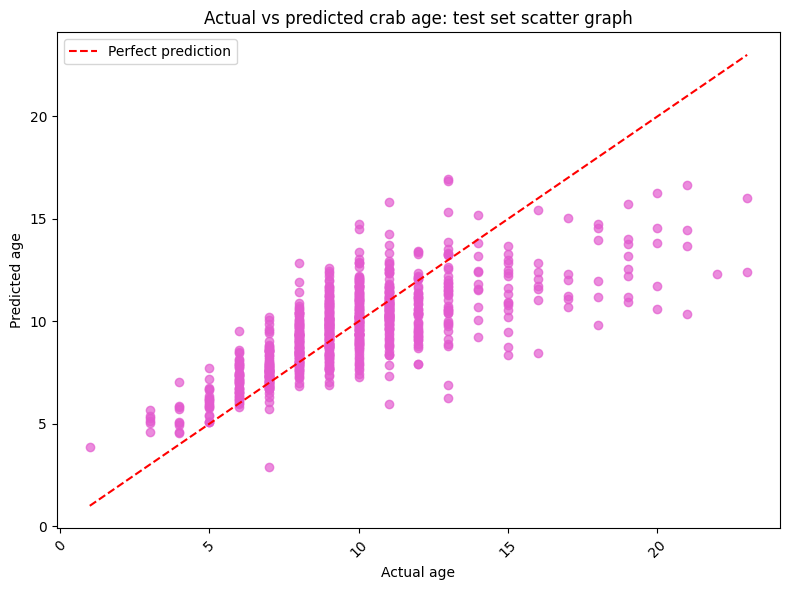

In [100]:
plt.figure(figsize=(8, 6))
plt.scatter(Y_test, crabAgePrediction, alpha=0.7, color="#e35bcf")

lowest_age = min(Y_test.min(), crabAgePrediction.min())
highest_age = max(Y_test.max(), crabAgePrediction.max())
plt.plot(
    [lowest_age, highest_age], [lowest_age, highest_age],
    "r--", label="Perfect prediction"
)

plt.xlabel("Actual age")
plt.ylabel("Predicted age")
plt.title("Actual vs predicted crab age: test set scatter graph")
plt.ticklabel_format(style="plain", axis="both")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()